# Figure 3

Panel a is a schematic. This notebook draws panels b–f from the source data.

Data: `Wilhelm_SourceData.xlsx` (one worksheet per panel) and the `Wilhelm_SourceData_*.parquet` / `*.csv` files of the figshare deposit (column descriptions in the deposit's `README.md`). Set `FIGSHARE_ARTICLE_ID` in the next cell (or as environment variable; while the article is private also `FIGSHARE_TOKEN`) to download the files into `./data`, or set `SOURCE_DATA_DIR` to a local copy of the deposit.

In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy.stats import gaussian_kde

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'Fig3'
FIG_DIR.mkdir(parents=True, exist_ok=True)


readme('Fig3')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Fig. 3,b,Fig3b,NaN,Amino-acid substitutions: delta monoisotopic m...,Fig3b
1,Fig. 3,c,Fig3c,NaN,95th percentile of the absolute delta iRT per ...,Fig3c
2,Fig. 3,d,Fig3d,NaN,Median spectral angle (HCD spectra carrying th...,Fig3d
3,Fig. 3,e,Fig3e,NaN,"Box-plot statistics (quartiles, whiskers 1.5 x...",Fig3e
4,Fig. 3,f,NaN,Wilhelm_SourceData_Fig3f.parquet; Wilhelm_Sour...,"Spectral angle per HCD spectrum, Prosit-22PTM ...",NaN


## Panel b — Amino acid substitutions

Delta monoisotopic mass (Da) vs spectral angle per amino-acid substitution, coloured by data set (train / validation / holdout).

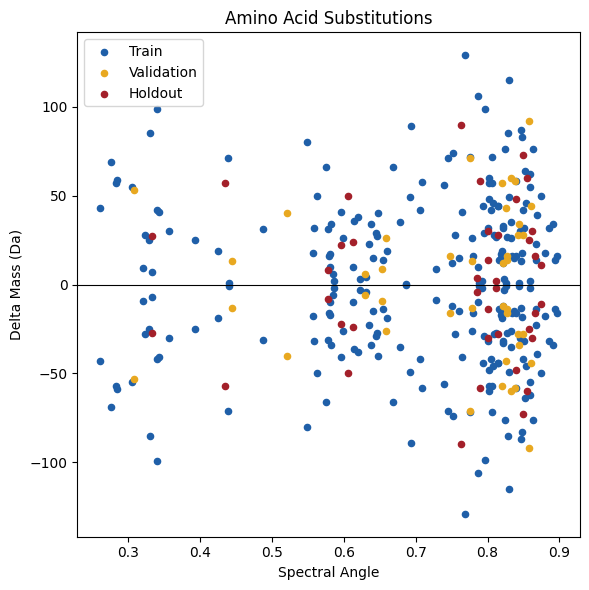

,substitution,from_aa,to_aa,set,delta_mono_mass_Da,spectral_angle,arrow_annotated,record_id,reverse_record_id
0,His->Asn,H,N,Train,-23.015984,0.634897,0,348,620
1,Ala->Ser,A,S,Train,15.994915,0.834061,1,540,648
2,Ala->Asp,A,D,Train,43.989829,0.814837,1,542,553
3,Ala->Pro,A,P,Train,26.015650,0.599105,0,543,624
4,Cys->Ser,C,S,Train,-15.977156,0.839419,0,548,654
...,...,...,...,...,...,...,...,...,...
338,Pro->Phe,P,F,Holdout,50.015650,0.605912,0,1169,1098
339,Gln->Cys,Q,C,Holdout,-25.049393,0.857593,0,1178,1064
340,Arg->Glu,R,E,Holdout,-27.058518,0.333267,0,1191,1085
341,Val->Cys,V,C,Holdout,3.940771,0.785767,0,1213,1066


In [3]:
b = table('Fig3b')
colors = {'Train': '#1f5fa8', 'Validation': '#e8a820', 'Holdout': '#a3202a'}
fig, ax = plt.subplots(figsize=(6, 6))
for s, col in colors.items():
    sub = b[b['set'] == s]
    ax.scatter(sub['spectral_angle'], sub['delta_mono_mass_Da'], c=col, s=20, label=s)
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('Spectral Angle')
ax.set_ylabel('Delta Mass (Da)')
ax.set_title('Amino Acid Substitutions')
ax.legend()
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig3b.{ext}', dpi=300, bbox_inches='tight')
plt.show()
b

## Panel c — Unseen PTMs iRT prediction error

95th percentile of the absolute ΔiRT per unseen PTM, without (x) and with (y) augmentation; dashed line = diagonal.

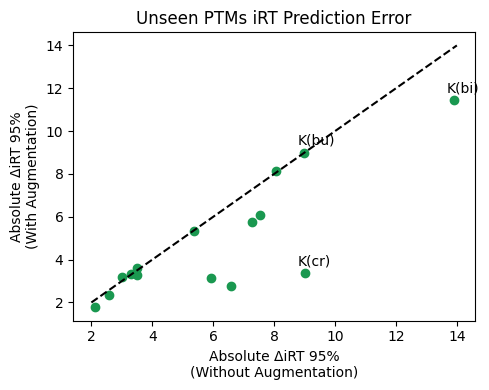

,PTM,package,abs_dIRT_95pct_without_augmentation (x),abs_dIRT_95pct_with_augmentation (y)
0,K(bi),Kmod_Biotin,13.891075,11.435152
1,K(bu),Kmod_Butyryl,8.995489,8.978553
2,K(cr),Kmod_Crotonyl,9.002179,3.353479
3,K(di),Kmod_Dimethyl,2.568999,2.357436
4,K(fo),Kmod_Formyl,3.302538,3.347496
5,K(gl),Kmod_Glutaryl,7.529937,6.079503
6,K(hy),Kmod_Hydroxyisobut,7.287979,5.778466
7,K(ma),Kmod_Malonyl,6.572988,2.786432
8,K(pr),Kmod_Propion,5.385318,5.331490
9,K(su),Kmod_Succinyl,5.922909,3.127426


In [4]:
cc = table('Fig3c')
x, y = cc['abs_dIRT_95pct_without_augmentation (x)'], cc['abs_dIRT_95pct_with_augmentation (y)']
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(x, y, color='#1a9850')
ax.plot([2, 14], [2, 14], 'k--')
for _, r in cc[cc['PTM'].isin(['K(bi)', 'K(bu)', 'K(cr)'])].iterrows():
    ax.annotate(r['PTM'], (r['abs_dIRT_95pct_without_augmentation (x)'], r['abs_dIRT_95pct_with_augmentation (y)']), textcoords='offset points', xytext=(-5, 6))
ax.set_xlabel('Absolute ΔiRT 95%\n(Without Augmentation)')
ax.set_ylabel('Absolute ΔiRT 95%\n(With Augmentation)')
ax.set_title('Unseen PTMs iRT Prediction Error')
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig3c.{ext}', dpi=300, bbox_inches='tight')
plt.show()
cc

## Panel d — Unseen PTMs FII prediction accuracy

Median spectral angle (HCD spectra carrying the PTM) per unseen PTM: atom-count encoding without augmentation (x) and gain-loss encoding with augmentation (y); dashed line = diagonal.

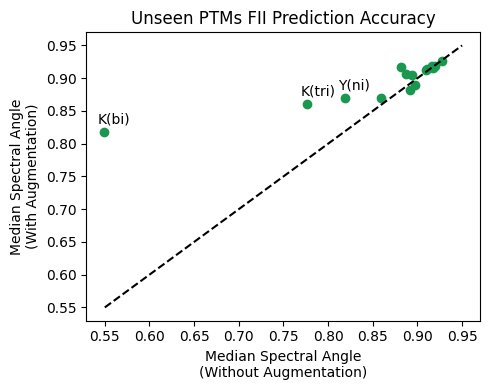

,PTM,package,median_SA_gain_loss_with_augmentation (y),median_SA_atom_count_without_augmentation (x),n_spectra_HCD
0,K(bi),Kmod_Biotin,0.817843,0.549238,4228
1,K(bu),Kmod_Butyryl,0.917462,0.881270,4848
2,K(cr),Kmod_Crotonyl,0.916217,0.917147,5372
3,K(di),Kmod_Dimethyl,0.869917,0.858669,5290
4,K(fo),Kmod_Formyl,0.914515,0.910889,5233
5,K(gl),Kmod_Glutaryl,0.905998,0.886869,5256
6,K(hy),Kmod_Hydroxyisobut,0.919299,0.916536,5166
7,K(ma),Kmod_Malonyl,0.919202,0.919230,3248
8,K(pr),Kmod_Propion,0.926366,0.927167,5753
9,K(su),Kmod_Succinyl,0.904770,0.893910,5072


In [5]:
d = table('Fig3d')
x, y = d['median_SA_atom_count_without_augmentation (x)'], d['median_SA_gain_loss_with_augmentation (y)']
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(x, y, color='#1a9850')
lim = [0.55, 0.95]
ax.plot(lim, lim, 'k--')
for _, r in d.iterrows():
    if r['PTM'] in ('K(bi)', 'K(tri)', 'Y(ni)'):
        ax.annotate(r['PTM'], (r['median_SA_atom_count_without_augmentation (x)'], r['median_SA_gain_loss_with_augmentation (y)']),
                    textcoords='offset points', xytext=(-5, 6))
ax.set_xlabel('Median Spectral Angle\n(Without Augmentation)')
ax.set_ylabel('Median Spectral Angle\n(With Augmentation)')
ax.set_title('Unseen PTMs FII Prediction Accuracy')
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig3d.{ext}', dpi=300, bbox_inches='tight')
plt.show()
d

## Panel e — iRT prediction error Prosit-22PTM vs DeepLC

Box plots of the absolute ΔiRT per unseen PTM, drawn from the box statistics (median, quartiles, whiskers at 1.5 × IQR, no outliers); n = unique peptides carrying the PTM.

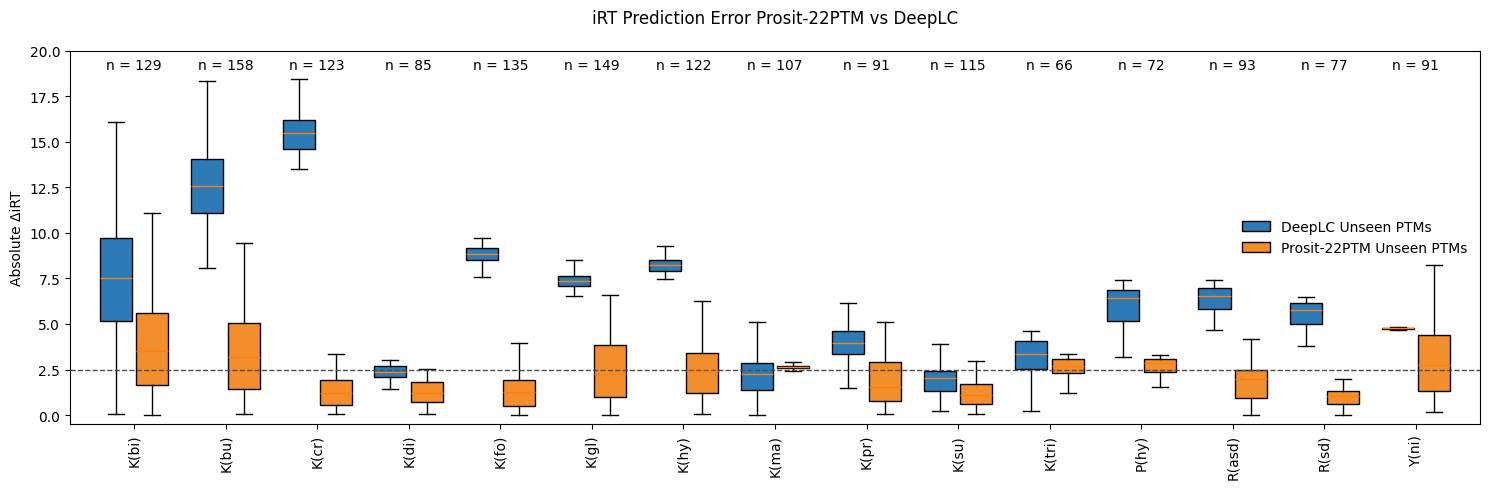

,PTM,package,model,"n (unique peptides carrying the PTM, n label)",n_peptides_plotted (carrying the PTM),lower_whisker,Q1,median,Q3,upper_whisker
0,K(bi),Kmod_Biotin,DeepLC,129,129,0.055569,5.141278,7.547561,9.742733,16.087320
1,K(bi),Kmod_Biotin,Prosit-22PTM,129,129,0.017988,1.659738,3.535604,5.600163,11.083302
2,K(bu),Kmod_Butyryl,DeepLC,158,158,8.064387,11.066554,12.600808,14.061178,18.358255
3,K(bu),Kmod_Butyryl,Prosit-22PTM,158,158,0.067471,1.454009,3.173592,5.043461,9.438420
4,K(cr),Kmod_Crotonyl,DeepLC,123,123,13.487400,14.615354,15.476289,16.206674,18.454344
5,K(cr),Kmod_Crotonyl,Prosit-22PTM,123,123,0.036224,0.529082,1.234656,1.920130,3.356273
6,K(di),Kmod_Dimethyl,DeepLC,85,85,1.411596,2.076721,2.374729,2.676446,3.006475
7,K(di),Kmod_Dimethyl,Prosit-22PTM,85,85,0.060324,0.697186,1.229127,1.839704,2.507574
8,K(fo),Kmod_Formyl,DeepLC,135,135,7.605157,8.513171,8.825433,9.156711,9.695210
9,K(fo),Kmod_Formyl,Prosit-22PTM,135,135,0.008453,0.506611,1.284423,1.924810,3.959671


In [6]:
e = table('Fig3e')
order = list(dict.fromkeys(e['PTM']))
colors = {'DeepLC': '#2c7bb6', 'Prosit-22PTM': '#f28e2b'}
fig, ax = plt.subplots(figsize=(15, 5))
for k, model in enumerate(['DeepLC', 'Prosit-22PTM']):
    stats = [dict(med=r['median'], q1=r['Q1'], q3=r['Q3'], whislo=r['lower_whisker'], whishi=r['upper_whisker'])
             for _, r in e[e['model'] == model].set_index('PTM').loc[order].reset_index().iterrows()]
    bp = ax.bxp(stats, positions=np.arange(len(order)) + (k - 0.5) * 0.4, widths=0.35, showfliers=False,
                patch_artist=True)
    for box in bp['boxes']:
        box.set_facecolor(colors[model])
    bp['boxes'][0].set_label(f'{model} Unseen PTMs')
for i, n in enumerate(e.drop_duplicates('PTM').set_index('PTM').loc[order, 'n (unique peptides carrying the PTM, n label)']):
    ax.text(i, 19, f'n = {n}', ha='center')
ax.axhline(2.5, color='0.3', ls='--', lw=1)
ax.set_xticks(range(len(order)), order, rotation=90)
ax.set_ylim(-0.5, 20)
ax.set_ylabel('Absolute ΔiRT')
ax.set_title('iRT Prediction Error Prosit-22PTM vs DeepLC', pad=20)
ax.legend(frameon=False)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig3e.{ext}', dpi=300, bbox_inches='tight')
plt.show()
e

## Panel f — FII prediction accuracy Prosit-22PTM vs AlphaPeptDeep

Spectral angle per HCD spectrum carrying the modification, split violins per PTM (AlphaPeptDeep left, Prosit-22PTM right), colour = model and whether the PTM was seen in training. Density: `scipy.stats.gaussian_kde` with Scott's bandwidth, evaluated on 100 points extending 2 bandwidths beyond the data (seaborn defaults `cut=2`, `gridsize=100`); each half scaled to the same maximum width. n labels = HCD spectra per PTM (`Wilhelm_SourceData_Fig3f_n.csv`).

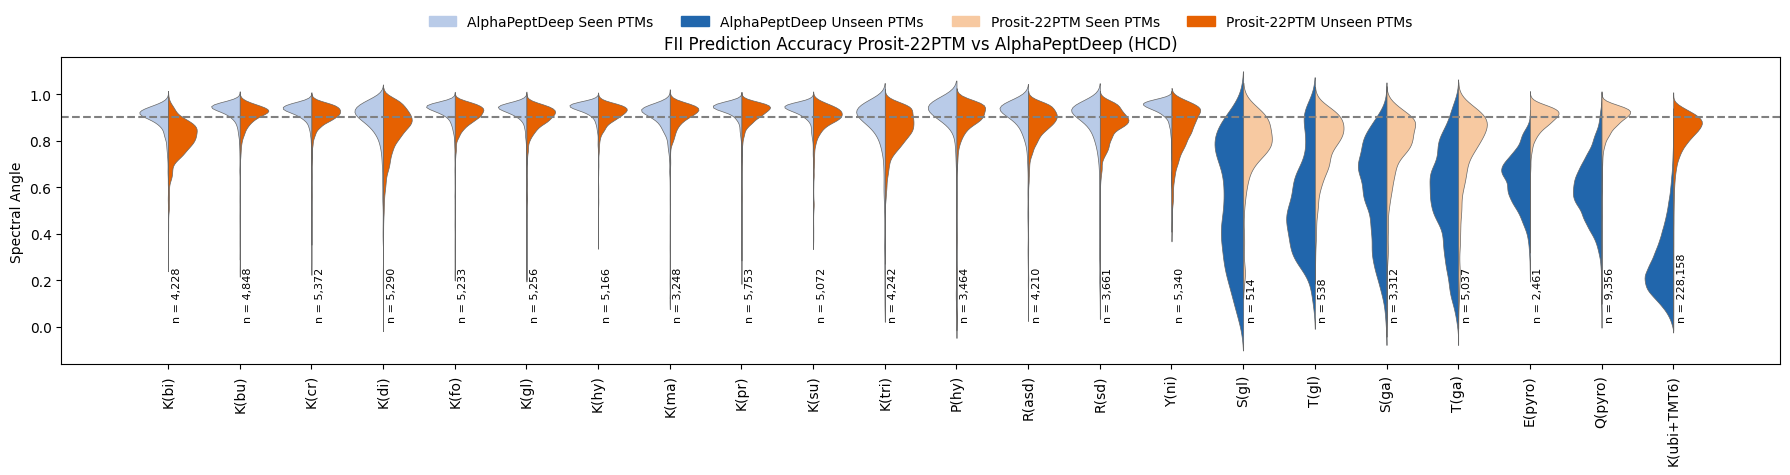

,PTM,Prosit-22PTM n_HCD,Prosit-22PTM n_all_fragmentations,Prosit-22PTM median_SA_HCD,AlphaPeptDeep n_HCD,AlphaPeptDeep n_all_fragmentations,AlphaPeptDeep median_SA_HCD
0,K(bi),4228,5935,0.817843,4228,5935,0.911188
1,K(bu),4848,6959,0.917462,4848,6959,0.938308
2,K(cr),5372,7417,0.916217,5372,7417,0.933918
3,K(di),5290,7371,0.869917,5290,7371,0.910239
4,K(fo),5233,7248,0.914515,5233,7248,0.938939
5,K(gl),5256,7204,0.905998,5256,7204,0.936800
6,K(hy),5166,7078,0.919299,5166,7078,0.943621
7,K(ma),3248,4699,0.919202,3248,4699,0.917819
8,K(pr),5753,7911,0.926366,5753,7911,0.940874
9,K(su),5072,7024,0.904770,5072,7024,0.937650


In [7]:
f = pd.read_parquet(fetch('Wilhelm_SourceData_Fig3f.parquet'))
f = f[f['fragmentation'] == 'HCD']
f_n = table('Fig3f_n')
order = f_n['PTM'].tolist()
palette = {('AlphaPeptDeep', 'Seen PTMs'): '#b9cbe8', ('AlphaPeptDeep', 'Unseen PTMs'): '#2166ac',
           ('Prosit-22PTM', 'Seen PTMs'): '#f7c9a1', ('Prosit-22PTM', 'Unseen PTMs'): '#e66101'}
# Kernel density as seaborn violinplot (bw_method='scott', cut=2, gridsize=100), drawn manually to allow four colours;
# each half scaled to the same maximum width.
fig, ax = plt.subplots(figsize=(18, 5))
for i, ptm in enumerate(order):
    for model, side in [('AlphaPeptDeep', -1), ('Prosit-22PTM', 1)]:
        s = f[(f['PTM'] == ptm) & (f['model'] == model)]
        if len(s) < 2:
            continue
        x = s['spectral_angle'].values
        kde = gaussian_kde(x, bw_method='scott')
        bw = kde.factor * x.std(ddof=1)
        grid = np.linspace(x.min() - 2 * bw, x.max() + 2 * bw, 100)
        dens = kde(grid)
        dens = dens / dens.max() * 0.4
        ax.fill_betweenx(grid, i, i + side * dens, color=palette[(model, s['ptm_status'].iloc[0])],
                         edgecolor='0.4', lw=0.5)
    n = f_n.loc[f_n['PTM'] == ptm, 'Prosit-22PTM n_HCD'].iloc[0]
    ax.text(i + 0.05, 0.02, f'n = {n:,}', rotation=90, va='bottom', fontsize=8)
ax.axhline(0.9, color='0.5', ls='--')
ax.set_xticks(range(len(order)), order, rotation=90)
ax.set_ylabel('Spectral Angle')
ax.set_title('FII Prediction Accuracy Prosit-22PTM vs AlphaPeptDeep (HCD)')
ax.legend(handles=[Patch(color=c, label=f'{m} {s}') for (m, s), c in palette.items()],
          ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.18), frameon=False)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig3f.{ext}', dpi=300, bbox_inches='tight')
plt.show()
f_n